# Nivelación 0a — Python, NumPy y Matplotlib desde la cueva

**RL a ciegas** · Nivelación 0a

Antes de entrenar agentes necesitamos tres herramientas: **Python** (el lenguaje), **NumPy** (cuentas con arreglos de números) y **Matplotlib** (gráficos). En vez de aprenderlas con ejemplos sueltos, vamos a **construir el juego de la cueva a mano**, de a poco.

La idea central viene de la visión por computadora (*computer vision*): **la cueva es una imagen**. Una grilla de casillas es una matriz de números; una matriz de números con tres canales es una foto en colores. Todo lo que sepamos hacer con imágenes lo vamos a poder hacer con la cueva.

Hoy vamos a ver:

1. Números y textos: el mapa como **lista de strings**.
2. Listas, rebanadas (*slicing*), bucles y comprensiones: recorrer la cueva fila por fila.
3. Diccionarios: de cada acción a su desplazamiento.
4. Funciones: `mover(pos, a)`.
5. Clases: una mini `Cueva` que ya se puede jugar.
6. NumPy: el mapa como arreglo de 0 y 1, máscaras y *broadcasting*.
7. La cueva como **imagen RGB**: colores, canales y pixeles.
8. Matplotlib: mapas lado a lado y un gráfico de líneas.
9. Cierre: el entorno "oficial" del curso, `cave_env.py`.

> Cómo usar este notebook: ejecutar las celdas en orden (Colab: *Entorno de ejecución → Ejecutar todas*). Tarda unos segundos. Este notebook, a diferencia de los demás, **no** empieza escribiendo `cave_env.py`: lo vamos a construir nosotros.

## Paso 1 — Números y strings: el mapa es texto

La forma más simple de guardar la cueva es escribirla como **texto**: una lista de renglones, donde `#` es pared, `.` es piso, `S` es el inicio y `G` la salida (*goal*). Así la vería un programador antes de dibujarla.

In [1]:
CUEVA = [
    "##############",
    "#S...#.......#",
    "#.##.#.####..#",
    "#.#..#....#..#",
    "#.#.####..#.##",
    "#.#......##..#",
    "#.####.#..#..#",
    "#......#.##..#",
    "###.####....G#",
    "##############",
]
for fila in CUEVA:
    print(fila)

##############
#S...#.......#
#.##.#.####..#
#.#..#....#..#
#.#.####..#.##
#.#......##..#
#.####.#..#..#
#......#.##..#
###.####....G#
##############


Cada renglón es un **string** (una cadena de caracteres). Con strings y números podemos hacer preguntas básicas: ¿cuántas filas y columnas hay?, ¿qué hay en una casilla?, ¿cuántas paredes hay en una fila? Fijate que Python **empieza a contar desde 0**: la fila 0 es el borde de arriba.

In [2]:
alto = len(CUEVA)            # número de filas (un int)
ancho = len(CUEVA[0])        # número de caracteres del primer renglón
print("alto =", alto, " ancho =", ancho, " casillas =", alto * ancho)

fila1 = CUEVA[1]             # un string
print("fila 1:", fila1)
print("¿qué hay en (1, 1)?", fila1[1])
print("paredes en la fila 1:", fila1.count("#"))
print("fracción de pared en la fila 1:", fila1.count("#") / ancho)   # la división da un float

es_pared = CUEVA[1][5] == "#"     # una comparación da un booleano: True o False
print("¿(1, 5) es pared?", es_pared)
print(f"Con f-strings armamos frases: la cueva mide {alto}×{ancho}.")

alto = 10  ancho = 14  casillas = 140
fila 1: #S...#.......#
¿qué hay en (1, 1)? S
paredes en la fila 1: 3
fracción de pared en la fila 1: 0.21428571428571427
¿(1, 5) es pared? True
Con f-strings armamos frases: la cueva mide 10×14.


## Paso 2 — Listas, rebanadas, bucles y comprensiones

`CUEVA` es una **lista**: una colección ordenada que se recorre con índices. Con **rebanadas** (`inicio:fin`, el fin no se incluye) sacamos pedazos, como recortar una imagen. Miremos la esquina de arriba a la izquierda, las primeras 4 filas y 6 columnas.

In [3]:
recorte = [fila[0:6] for fila in CUEVA[0:4]]   # filas 0..3, columnas 0..5
for fila in recorte:
    print(fila)

print("última fila:", CUEVA[-1])      # los índices negativos cuentan desde el final
print("fila 1 al revés:", CUEVA[1][::-1])

######
#S...#
#.##.#
#.#..#
última fila: ##############
fila 1 al revés: #.......#...S#


Un **bucle** `for` recorre la cueva casilla por casilla. `enumerate` nos da a la vez el índice y el elemento. Vamos a juntar en una lista todas las casillas libres como **tuplas** `(fila, columna)` y a buscar el inicio y la salida.

In [4]:
libres = []
for r, fila in enumerate(CUEVA):
    for c, caracter in enumerate(fila):
        if caracter != "#":
            libres.append((r, c))
        if caracter == "S":
            inicio = (r, c)
        if caracter == "G":
            salida = (r, c)

print("casillas libres:", len(libres))
print("las primeras cinco:", libres[:5])
print("inicio:", inicio, " salida:", salida)

casillas libres: 60
las primeras cinco: [(1, 1), (1, 2), (1, 3), (1, 4), (1, 6)]
inicio: (1, 1)  salida: (8, 12)


Lo mismo, en una sola línea, con una **comprensión de lista** (*list comprehension*): "dame `(r, c)` para cada casilla que no sea pared". Es la forma más común de escribir estos recorridos en Python. Y un **conjunto** (`set`) sirve para preguntar rápido "¿esta casilla está?".

In [5]:
libres2 = [(r, c) for r, fila in enumerate(CUEVA) for c, ch in enumerate(fila) if ch != "#"]
print("¿da lo mismo?", libres2 == libres)

paredes = {(r, c) for r, fila in enumerate(CUEVA) for c, ch in enumerate(fila) if ch == "#"}
print("paredes:", len(paredes), " ¿(0, 0) es pared?", (0, 0) in paredes, " ¿(1, 1)?", (1, 1) in paredes)

¿da lo mismo? True
paredes: 80  ¿(0, 0) es pared? True  ¿(1, 1)? False


## Paso 3 — Diccionarios: nombres para las cosas

Un **diccionario** asocia claves con valores. Lo usamos dos veces:

- de cada **acción** (0, 1, 2, 3) a su **desplazamiento** `(Δfila, Δcolumna)`;
- de cada **casilla** `(r, c)` a su **número de estado** (0, 1, 2, …). Los algoritmos de RL prefieren estados numerados; el número es el índice en la lista `libres`.

In [6]:
ACCIONES = {0: (-1, 0), 1: (0, 1), 2: (1, 0), 3: (0, -1)}
NOMBRES = ["↑", "→", "↓", "←"]
for a, (dr, dc) in ACCIONES.items():
    print(f"acción {a} {NOMBRES[a]}: fila {dr:+d}, columna {dc:+d}")

pos2s = {pos: s for s, pos in enumerate(libres)}   # casilla -> número de estado
print("\nel inicio", inicio, "es el estado", pos2s[inicio])
print("la salida", salida, "es el estado", pos2s[salida])
print("y el estado 10 es la casilla", libres[10])

acción 0 ↑: fila -1, columna +0
acción 1 →: fila +0, columna +1
acción 2 ↓: fila +1, columna +0
acción 3 ←: fila +0, columna -1

el inicio (1, 1) es el estado 0
la salida (8, 12) es el estado 59
y el estado 10 es la casilla (1, 12)


## Paso 4 — Funciones: la regla del juego

La regla de la cueva cabe en una **función**: "si hago `a` desde `pos`, ¿adónde llego?, ¿choqué?". Si la casilla de destino es pared, me quedo donde estaba y aviso que choqué. Una función devuelve resultados con `return` (acá, dos cosas a la vez).

In [7]:
def mover(pos, a, mapa=CUEVA):
    '''Devuelve (nueva_pos, choque) al intentar la acción a desde pos.'''
    r, c = pos
    dr, dc = ACCIONES[a]
    nr, nc = r + dr, c + dc
    if mapa[nr][nc] == "#":
        return pos, True
    return (nr, nc), False

print("desde S hacia ↑:", mover(inicio, 0))
print("desde S hacia →:", mover(inicio, 1))
print("desde S hacia ↓:", mover(inicio, 2))

desde S hacia ↑: ((1, 1), True)
desde S hacia →: ((1, 2), False)
desde S hacia ↓: ((2, 1), False)


## Paso 5 — Clases: una cueva que se puede jugar

Una **clase** junta datos (el mapa, la posición, las paredes tocadas) con las funciones que los usan (los **métodos**). Vamos a escribir una mini `Cueva` con la misma forma que usan las bibliotecas de RL:

- `reset()` vuelve al inicio;
- `step(a)` hace una acción y devuelve `(estado, recompensa, terminado)`.

Además guarda en `tocadas` las paredes que el jugador va descubriendo, como en el juego.

In [8]:
class Cueva:
    def __init__(self, mapa=CUEVA, max_pasos=200):
        self.mapa = mapa
        self.max_pasos = max_pasos
        self.libres = [(r, c) for r, f in enumerate(mapa) for c, ch in enumerate(f) if ch != "#"]
        self.pos2s = {p: s for s, p in enumerate(self.libres)}
        self.inicio = next(p for p in self.libres if mapa[p[0]][p[1]] == "S")
        self.salida = next(p for p in self.libres if mapa[p[0]][p[1]] == "G")
        self.reset()

    def reset(self):
        self.pos, self.pasos, self.tocadas = self.inicio, 0, set()
        return self.pos2s[self.pos]

    def step(self, a):
        nueva, choque = mover(self.pos, a, self.mapa)
        if choque:
            dr, dc = ACCIONES[a]
            self.tocadas.add((self.pos[0] + dr, self.pos[1] + dc))
        self.pos, self.pasos = nueva, self.pasos + 1
        llego = nueva == self.salida
        recompensa = 1.0 if llego else 0.0
        terminado = llego or self.pasos >= self.max_pasos
        return self.pos2s[nueva], recompensa, terminado

cueva = Cueva()
print("estado inicial:", cueva.reset())
for a in [1, 1, 1, 0]:          # → → → ↑   (el último choca)
    print(NOMBRES[a], "->", cueva.step(a), " paredes tocadas:", cueva.tocadas)

estado inicial: 0
→ -> (1, 0.0, False)  paredes tocadas: set()
→ -> (2, 0.0, False)  paredes tocadas: set()
→ -> (3, 0.0, False)  paredes tocadas: set()
↑ -> (3, 0.0, False)  paredes tocadas: {(0, 4)}


Ya podemos jugar con el agente más simple: uno que elige acciones **al azar**. Usamos el módulo `random` con una **semilla** fija para que el resultado se repita cada vez que ejecutamos.

In [9]:
import random
random.seed(0)

cueva = Cueva()
s = cueva.reset()
camino = [cueva.pos]
terminado = False
while not terminado:
    s, recompensa, terminado = cueva.step(random.choice([0, 1, 2, 3]))
    camino.append(cueva.pos)

print("pasos:", cueva.pasos, " ¿llegó?", recompensa == 1.0, " paredes tocadas:", len(cueva.tocadas))

pasos: 200  ¿llegó? False  paredes tocadas: 17


## Paso 6 — NumPy: el mapa como matriz

Las listas de strings son cómodas para leer, pero lentas e incómodas para hacer cuentas. **NumPy** guarda números en un **arreglo** (*array*) de tamaño fijo y opera con todos a la vez. Convertimos el mapa en una matriz de 0 (piso) y 1 (pared).

In [10]:
import numpy as np

A = np.array([[1 if ch == "#" else 0 for ch in fila] for fila in CUEVA])
print(A)
print("forma (shape):", A.shape, "  tipo (dtype):", A.dtype)
print("A[1, 5] =", A[1, 5], "  paredes en total:", A.sum(), "  fracción de pared:", A.mean().round(2))

[[1 1 1 1 1 1 1 1 1 1 1 1 1 1]
 [1 0 0 0 0 1 0 0 0 0 0 0 0 1]
 [1 0 1 1 0 1 0 1 1 1 1 0 0 1]
 [1 0 1 0 0 1 0 0 0 0 1 0 0 1]
 [1 0 1 0 1 1 1 1 0 0 1 0 1 1]
 [1 0 1 0 0 0 0 0 0 1 1 0 0 1]
 [1 0 1 1 1 1 0 1 0 0 1 0 0 1]
 [1 0 0 0 0 0 0 1 0 1 1 0 0 1]
 [1 1 1 0 1 1 1 1 0 0 0 0 0 1]
 [1 1 1 1 1 1 1 1 1 1 1 1 1 1]]
forma (shape): (10, 14)   tipo (dtype): int64
A[1, 5] = 1   paredes en total: 80   fracción de pared: 0.57


El **indexado** de NumPy usa `A[fila, columna]`, y las rebanadas funcionan en las dos dimensiones a la vez. Una **máscara booleana** es una matriz de `True`/`False` del mismo tamaño: sirve para preguntar "¿dónde?" sin escribir bucles.

In [11]:
print("recorte A[0:4, 0:6]:\n", A[0:4, 0:6])
print("columna 12:", A[:, 12])

es_pared = A == 1                       # máscara: True donde hay pared
print("\nmáscara (primeras 3 filas):\n", es_pared[:3])
print("paredes del interior (sin el borde):", es_pared[1:-1, 1:-1].sum())
print("coordenadas de las casillas libres (primeras 5):\n", np.argwhere(~es_pared)[:5])

recorte A[0:4, 0:6]:
 [[1 1 1 1 1 1]
 [1 0 0 0 0 1]
 [1 0 1 1 0 1]
 [1 0 1 0 0 1]]
columna 12: [1 0 0 0 1 0 0 0 0 1]

máscara (primeras 3 filas):
 [[ True  True  True  True  True  True  True  True  True  True  True  True
   True  True]
 [ True False False False False  True False False False False False False
  False  True]
 [ True False  True  True False  True False  True  True  True  True False
  False  True]]
paredes del interior (sin el borde): 36
coordenadas de las casillas libres (primeras 5):
 [[1 1]
 [1 2]
 [1 3]
 [1 4]
 [1 6]]


Una cuenta típica de visión: **mirar a los vecinos**. Si corremos la matriz una casilla hacia cada lado (con rebanadas) y sumamos, obtenemos, para cada casilla, **cuántas paredes la rodean**. Es lo mismo que hace un filtro de convolución en una imagen. Las casillas libres con 3 paredes alrededor son **callejones sin salida**.

In [12]:
vecinas = np.zeros_like(A)
vecinas[1:-1, 1:-1] = A[:-2, 1:-1] + A[2:, 1:-1] + A[1:-1, :-2] + A[1:-1, 2:]   # arriba+abajo+izq+der
vecinas[es_pared] = -1                     # marcamos las paredes con -1 para no confundir
print(vecinas)

callejones = np.argwhere(vecinas == 3)
print("callejones sin salida:", [tuple(int(x) for x in p) for p in callejones])

[[-1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1]
 [-1  2  2  2  2 -1  2  2  2  2  2  1  2 -1]
 [-1  2 -1 -1  2 -1  2 -1 -1 -1 -1  1  1 -1]
 [-1  2 -1  2  2 -1  2  2  1  2 -1  1  2 -1]
 [-1  2 -1  2 -1 -1 -1 -1  1  2 -1  2 -1 -1]
 [-1  2 -1  2  2  2  1  2  1 -1 -1  1  2 -1]
 [-1  2 -1 -1 -1 -1  2 -1  1  3 -1  1  1 -1]
 [-1  2  2  1  2  2  2 -1  2 -1 -1  1  1 -1]
 [-1 -1 -1  3 -1 -1 -1 -1  2  2  2  1  2 -1]
 [-1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1]]
callejones sin salida: [(6, 9), (8, 3)]


**Broadcasting** (difusión): NumPy sabe operar arreglos de formas distintas "estirando" el más chico. Con eso calculamos de un saque **los 4 vecinos de las 60 casillas**:

- `L` tiene forma `(60, 2)`: las posiciones libres;
- `D` tiene forma `(4, 2)`: los desplazamientos;
- `L[:, None, :] + D[None, :, :]` tiene forma `(60, 4, 2)`: para cada casilla y cada acción, adónde intentaría ir.

Después, con **indexado por arreglos**, preguntamos a la matriz `A` si cada destino es pared.

In [13]:
L = np.argwhere(A == 0)                          # (60, 2)
D = np.array([ACCIONES[a] for a in range(4)])     # (4, 2)
destinos = L[:, None, :] + D[None, :, :]         # (60, 4, 2)
print("formas:", L.shape, "+", D.shape, "->", destinos.shape)

choca = A[destinos[..., 0], destinos[..., 1]] == 1    # (60, 4): ¿la acción a choca en la casilla s?
print("desde S (estado 0), ¿choca cada acción?", dict(zip(NOMBRES, choca[0].tolist())))
print(f"un agente al azar choca en el {choca.mean():.0%} de los pasos (promedio sobre casillas)")

formas: (60, 2) + (4, 2) -> (60, 4, 2)
desde S (estado 0), ¿choca cada acción? {'↑': True, '→': False, '↓': False, '←': True}
un agente al azar choca en el 44% de los pasos (promedio sobre casillas)


¿Para qué tanto lío? Porque **vectorizar** (operar con arreglos enteros en vez de bucles) es muchísimo más rápido. Comparemos chequear un millón de intentos con un bucle de Python y con NumPy.

In [14]:
import time
rng = np.random.default_rng(0)
idx_s = rng.integers(0, len(L), size=1_000_000)
idx_a = rng.integers(0, 4, size=1_000_000)

t0 = time.perf_counter()
n_bucle = sum(mover(tuple(L[s]), a)[1] for s, a in zip(idx_s[:100_000], idx_a[:100_000])) * 10
t_bucle = (time.perf_counter() - t0) * 10          # extrapolado de 100 mil a un millón
t0 = time.perf_counter()
n_numpy = choca[idx_s, idx_a].sum()
t_numpy = time.perf_counter() - t0
print(f"bucle (estimado): {t_bucle:.2f} s    NumPy: {t_numpy * 1000:.1f} ms    ->  ~{t_bucle / t_numpy:.0f} veces más rápido")
print("choques: bucle ≈", n_bucle, "  NumPy =", n_numpy)

bucle (estimado): 1.06 s    NumPy: 3.8 ms    ->  ~279 veces más rápido
choques: bucle ≈ 442610   NumPy = 441400


## Paso 7 — La cueva como imagen RGB

Una foto en colores es un arreglo de forma `(alto, ancho, 3)`: tres números por pixel, para el **rojo**, el **verde** y el **azul** (canales RGB), entre 0 y 1. Armemos la cueva así: fondo negro (la oscuridad), paredes gris claro, salida verde, inicio blanco. Cada color se pinta con una máscara.

forma de la imagen: (10, 14, 3)


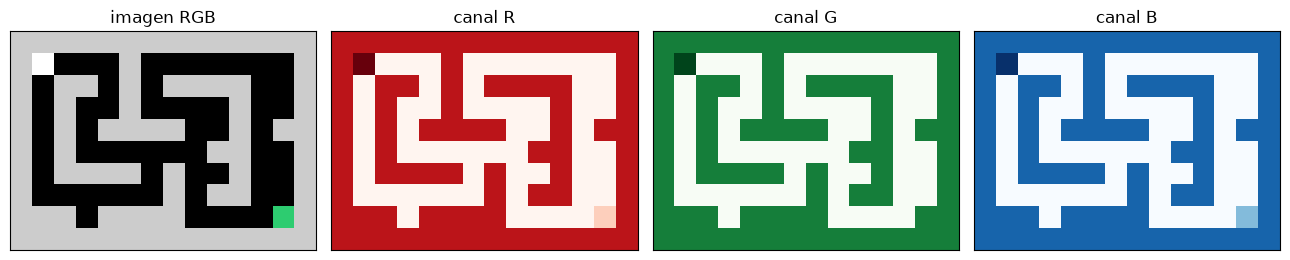

In [15]:
import matplotlib.pyplot as plt
plt.rcParams["figure.dpi"] = 100

H, W = A.shape
img = np.zeros((H, W, 3))                 # todo negro
img[A == 1] = [0.8, 0.8, 0.8]             # gris claro donde hay pared
img[salida] = [0.18, 0.80, 0.44]          # verde
img[inicio] = [1.0, 1.0, 1.0]             # blanco
print("forma de la imagen:", img.shape)

fig, axs = plt.subplots(1, 4, figsize=(13, 2.6))
axs[0].imshow(img); axs[0].set_title("imagen RGB")
for k, (nombre, cmap) in enumerate([("canal R", "Reds"), ("canal G", "Greens"), ("canal B", "Blues")]):
    axs[k + 1].imshow(img[:, :, k], cmap=cmap, vmin=0, vmax=1); axs[k + 1].set_title(nombre)
for ax in axs:
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

Cada casilla es **un** pixel: por eso la imagen es tan chica (14×10). En los canales se ve qué aporta cada color: la salida brilla en el verde y casi no en el rojo; las paredes y el inicio brillan en los tres (gris y blanco son "todos los colores por igual").

Para agrandarla **sin suavizar**, como en un juego de pixeles, repetimos cada casilla en un bloque de `k×k`. Hay dos formas: `np.repeat` (repetir a lo largo de un eje) y `np.kron` (producto de Kronecker con un bloque de unos). Después usamos rebanadas para dibujar una grilla y al jugador.

forma: (10, 14, 3) -> (120, 168, 3)   ¿iguales? True


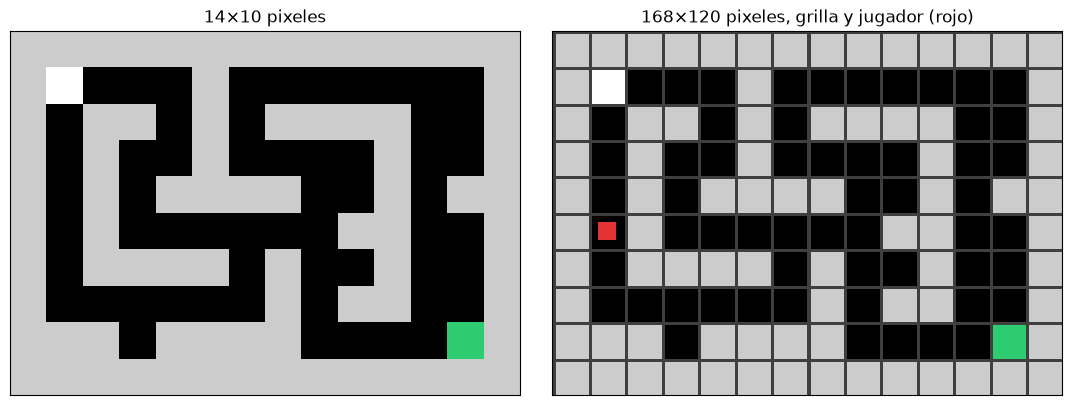

In [16]:
k = 12
grande = np.repeat(np.repeat(img, k, axis=0), k, axis=1)        # (H*k, W*k, 3)
grande2 = np.kron(img, np.ones((k, k, 1)))                      # lo mismo con Kronecker
print("forma:", img.shape, "->", grande.shape, "  ¿iguales?", np.allclose(grande, grande2))

con_grilla = grande.copy()
con_grilla[::k, :, :] = 0.25          # una línea gris oscura cada k pixeles (filas)
con_grilla[:, ::k, :] = 0.25          # ... y columnas

r, c = camino[60]                     # dónde estaba el agente al azar en el paso 60
con_grilla[r * k + 3:(r + 1) * k - 3, c * k + 3:(c + 1) * k - 3] = [0.9, 0.2, 0.2]   # un cuadrado rojo

fig, axs = plt.subplots(1, 2, figsize=(11, 4))
axs[0].imshow(img); axs[0].set_title(f"{img.shape[1]}×{img.shape[0]} pixeles")
axs[1].imshow(con_grilla); axs[1].set_title(f"{grande.shape[1]}×{grande.shape[0]} pixeles, grilla y jugador (rojo)")
for ax in axs:
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

## Paso 8 — Matplotlib: lo que hay vs. lo que se ve

Con `plt.subplots` armamos varias figuras en una. A la izquierda, el **mapa real**. A la derecha, **lo que sabe el jugador** después de la partida al azar del Paso 5: todo negro salvo las paredes que tocó (gris claro), con su recorrido en azul. Así se ve la cueva en el juego.

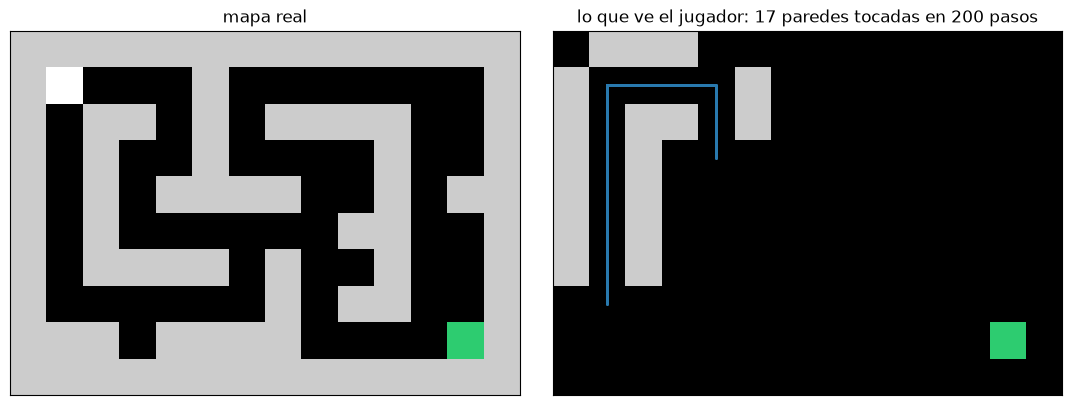

In [17]:
vista = np.zeros((H, W, 3))
for (r, c) in cueva.tocadas:
    vista[r, c] = [0.8, 0.8, 0.8]
vista[salida] = [0.18, 0.80, 0.44]

rc = np.array(camino)                     # (pasos+1, 2): filas y columnas del recorrido

fig, axs = plt.subplots(1, 2, figsize=(11, 4))
axs[0].imshow(img); axs[0].set_title("mapa real")
axs[1].imshow(vista)
axs[1].plot(rc[:, 1], rc[:, 0], "-", color="#3498db", lw=2, alpha=0.8)   # x = columna, y = fila
axs[1].set_title(f"lo que ve el jugador: {len(cueva.tocadas)} paredes tocadas en {cueva.pasos} pasos")
for ax in axs:
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

Ojo con un detalle de `imshow`: la **fila** es el eje vertical (`y`) y la **columna** el horizontal (`x`). Por eso en `plot` pasamos primero las columnas y después las filas.

Último gráfico: un **gráfico de líneas**. Hacemos jugar 200 partidas al agente al azar (cada una corta a los 200 pasos) y dibujamos cuántos pasos usó en cada una. Las partidas que tocan el techo de 200 son las que **no** encontraron la salida.

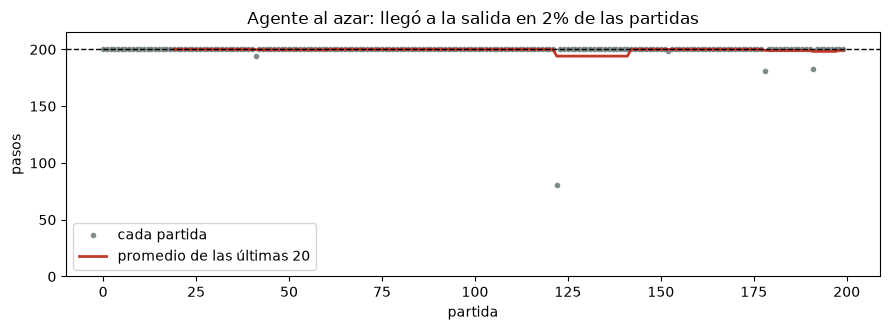

In [18]:
random.seed(1)
cueva = Cueva(max_pasos=200)
pasos_por_partida = []
for partida in range(200):
    cueva.reset()
    terminado = False
    while not terminado:
        _, recompensa, terminado = cueva.step(random.choice([0, 1, 2, 3]))
    pasos_por_partida.append(cueva.pasos)

pasos_por_partida = np.array(pasos_por_partida)
promedio_movil = np.convolve(pasos_por_partida, np.ones(20) / 20, mode="valid")

fig, ax = plt.subplots(figsize=(9, 3.4))
ax.plot(pasos_por_partida, ".", color="#7f8c8d", label="cada partida")
ax.plot(np.arange(19, 200), promedio_movil, "-", color="#c0392b", lw=2, label="promedio de las últimas 20")
ax.axhline(200, color="k", ls="--", lw=1)
ax.set_xlabel("partida"); ax.set_ylabel("pasos"); ax.set_ylim(0, 215)
ax.set_title(f"Agente al azar: llegó a la salida en {np.mean(pasos_por_partida < 200):.0%} de las partidas")
ax.legend(loc="lower left"); plt.tight_layout(); plt.show()

Casi todas las partidas se quedan en el techo: un agente que no aprende **casi nunca** sale. Y el promedio móvil no baja, porque no aprende nada de una partida a la siguiente. Esa línea roja es la que, en el resto del curso, vamos a querer ver **bajar**.

## ✍️ Ejercicio 1 — Rediseñar la cueva

Cambiá el mapa `MI_CUEVA` (por ejemplo, tapá el pasillo de la derecha poniendo `#` en la fila 1, o abrí un atajo) y ejecutá. La celda redibuja la imagen y vuelve a contar casillas libres y callejones. Regla: el borde tiene que ser todo `#` y tiene que haber un `S` y un `G`.

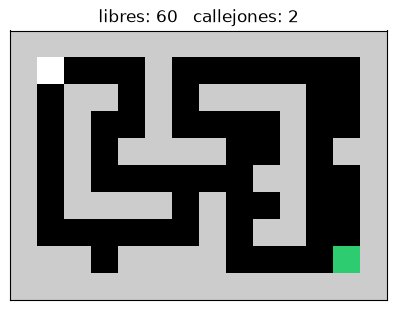

In [19]:
MI_CUEVA = [
    "##############",
    "#S...#.......#",
    "#.##.#.####..#",
    "#.#..#....#..#",
    "#.#.####..#.##",
    "#.#......##..#",
    "#.####.#..#..#",
    "#......#.##..#",
    "###.####....G#",
    "##############",
]   # TODO: cambiá algún '.' por '#' (o al revés)

B = np.array([[1 if ch == "#" else 0 for ch in fila] for fila in MI_CUEVA])
vec = np.zeros_like(B)
vec[1:-1, 1:-1] = B[:-2, 1:-1] + B[2:, 1:-1] + B[1:-1, :-2] + B[1:-1, 2:]
n_callejones = int(((vec == 3) & (B == 0)).sum())
im2 = np.zeros(B.shape + (3,)); im2[B == 1] = 0.8
for r, fila in enumerate(MI_CUEVA):
    for c, ch in enumerate(fila):
        if ch == "G": im2[r, c] = [0.18, 0.80, 0.44]
        if ch == "S": im2[r, c] = 1.0
plt.figure(figsize=(5, 3.5)); plt.imshow(im2); plt.xticks([]); plt.yticks([])
plt.title(f"libres: {(B == 0).sum()}   callejones: {n_callejones}"); plt.show()

## ✍️ Ejercicio 2 — Más paciencia

Cambiá `paciencia` (el máximo de pasos por partida: probá 500 y 2000) y mirá qué fracción de partidas llega a la salida. ¿Crece mucho? ¿Cuánto tarda en promedio el agente al azar?

In [20]:
paciencia = 200   # TODO: probá 500 y 2000

random.seed(2)
cueva_ej = Cueva(max_pasos=paciencia)
largos = []
for _ in range(200):
    cueva_ej.reset(); terminado = False
    while not terminado:
        _, recompensa, terminado = cueva_ej.step(random.choice([0, 1, 2, 3]))
    largos.append(cueva_ej.pasos)
largos = np.array(largos)
print(f"paciencia {paciencia}: llegó en {np.mean(largos < paciencia):.0%} de las partidas;"
      f" pasos promedio de las que llegaron: {largos[largos < paciencia].mean() if (largos < paciencia).any() else float('nan'):.0f}")

paciencia 200: llegó en 2% de las partidas; pasos promedio de las que llegaron: 128


## Paso 9 — Ya construiste el juego

Todo lo que necesita el curso ya está en este notebook: el mapa, las acciones, la regla de movimiento, la clase con `reset` y `step`, la imagen y los gráficos. Desde ahora usamos una versión "oficial" y un poco más completa: el archivo **`cave_env.py`**. La celda siguiente lo escribe en disco (lo mismo va a hacer la primera celda de cada clase). Si lo leés, vas a reconocer casi todo:

- `CAVE_MAP`, `ACTIONS` y `ACTION_NAMES` son nuestros `CUEVA`, `ACCIONES` y `NOMBRES`;
- `CaveEnv._move` es nuestra `mover`, y `free` / `pos2s` son `libres` / `pos2s`;
- `CaveEnv.plot` dibuja la cueva igual que el Paso 7, con un mapa de calor encima.

Lo nuevo: el piso resbaloso (`slip`, nivelación 0b), el modelo `P` y `R` (nivelación 0c y clase 4) y las observaciones para redes (clase 8).

In [21]:
%%writefile cave_env.py
"""
cave_env.py — La cueva a ciegas (entorno del mini curso de RL).

Una grilla discreta. El agente no ve el mapa: solo se entera de que hay una
pared cuando choca contra ella (en el juego, la pared se pinta de gris claro).
La salida es el cuadrado verde 'G'.

API mínima (estilo Gymnasium, sin dependencias):
    env = CaveEnv()
    s = env.reset()                 # estado = índice entero de la casilla
    s, r, done, info = env.step(a)  # a en {0:arriba, 1:derecha, 2:abajo, 3:izquierda}
    info["bump"]                    # True si chocó con una pared

Para la clase 4 (planificar con mapa): env.P[s, a, s'] y env.R[s, a].
"""
import numpy as np

CAVE_MAP = [
    "##############",
    "#S...#.......#",
    "#.##.#.####..#",
    "#.#..#....#..#",
    "#.#.####..#.##",
    "#.#......##..#",
    "#.####.#..#..#",
    "#......#.##..#",
    "###.####....G#",
    "##############",
]

ACTIONS = {0: (-1, 0), 1: (0, 1), 2: (1, 0), 3: (0, -1)}
ACTION_NAMES = ["↑", "→", "↓", "←"]


class CaveEnv:
    def __init__(self, cave_map=CAVE_MAP, goal_reward=1.0, step_reward=0.0,
                 bump_reward=0.0, slip=0.0, max_steps=200, seed=None):
        self.grid = np.array([list(row) for row in cave_map])
        self.H, self.W = self.grid.shape
        self.goal_reward, self.step_reward, self.bump_reward = goal_reward, step_reward, bump_reward
        self.slip, self.max_steps = slip, max_steps
        self.rng = np.random.default_rng(seed)
        self.free = [(r, c) for r in range(self.H) for c in range(self.W) if self.grid[r, c] != "#"]
        self.pos2s = {p: i for i, p in enumerate(self.free)}
        self.nS, self.nA = len(self.free), 4
        self.start = self.pos2s[tuple(np.argwhere(self.grid == "S")[0])]
        self.goal = self.pos2s[tuple(np.argwhere(self.grid == "G")[0])]
        self._build_model()
        self.reset()

    # ---------- dinámica ----------
    def _move(self, s, a):
        r, c = self.free[s]
        dr, dc = ACTIONS[a]
        nr, nc = r + dr, c + dc
        if self.grid[nr, nc] == "#":
            return s, True
        return self.pos2s[(nr, nc)], False

    def _reward(self, s_next, bump):
        if s_next == self.goal:
            return self.goal_reward
        return self.step_reward + (self.bump_reward if bump else 0.0)

    def _build_model(self):
        """Modelo del mundo: P[s,a,s'] y R[s,a] (recompensa esperada). La meta es absorbente."""
        nS, nA = self.nS, self.nA
        self.P = np.zeros((nS, nA, nS))
        self.R = np.zeros((nS, nA))
        for s in range(nS):
            for a in range(nA):
                if s == self.goal:
                    self.P[s, a, s] = 1.0
                    continue
                # con prob 1-slip va adonde quiere; con slip, a una dirección perpendicular
                outcomes = [(a, 1 - self.slip)]
                if self.slip > 0:
                    outcomes += [((a + 1) % 4, self.slip / 2), ((a + 3) % 4, self.slip / 2)]
                for aa, p in outcomes:
                    s2, bump = self._move(s, aa)
                    self.P[s, a, s2] += p
                    self.R[s, a] += p * self._reward(s2, bump)

    def reset(self):
        self.s, self.t = self.start, 0
        self.touched = set()          # paredes descubiertas (para dibujar)
        return self.s

    def step(self, a):
        if self.slip > 0 and self.rng.random() < self.slip:
            a = (a + self.rng.choice([1, 3])) % 4
        s2, bump = self._move(self.s, a)
        if bump:
            r, c = self.free[self.s]
            dr, dc = ACTIONS[a]
            self.touched.add((r + dr, c + dc))
        rew = self._reward(s2, bump)
        self.s, self.t = s2, self.t + 1
        done = s2 == self.goal or self.t >= self.max_steps
        return s2, rew, done, {"bump": bump, "reached_goal": s2 == self.goal}

    # ---------- observaciones para Deep RL ----------
    def observe(self, s=None, kind="onehot"):
        s = self.s if s is None else s
        if kind == "onehot":
            x = np.zeros(self.nS, dtype=np.float32); x[s] = 1; return x
        r, c = self.free[s]
        if kind == "coords":
            return np.array([r / (self.H - 1), c / (self.W - 1)], dtype=np.float32)
        if kind == "coords+touch":   # posición + 4 "bigotes" que sienten paredes vecinas
            walls = [float(self.grid[r + dr, c + dc] == "#") for dr, dc in ACTIONS.values()]
            return np.array([r / (self.H - 1), c / (self.W - 1)] + walls, dtype=np.float32)
        raise ValueError(kind)

    # ---------- dibujo ----------
    def to_grid(self, values):
        g = np.full((self.H, self.W), np.nan)
        for s, (r, c) in enumerate(self.free):
            g[r, c] = values[s]
        return g

    def plot(self, values=None, policy=None, ax=None, title=None, cmap="magma",
             show_walls=True, path=None):
        import matplotlib.pyplot as plt
        if ax is None:
            _, ax = plt.subplots(figsize=(self.W * 0.5, self.H * 0.5))
        bg = np.zeros((self.H, self.W, 3))
        if show_walls:
            bg[self.grid == "#"] = 0.8      # gris claro: la pared "tocada"
        ax.imshow(bg)
        if values is not None:
            im = ax.imshow(self.to_grid(values), cmap=cmap, alpha=0.9)
            plt.colorbar(im, ax=ax, fraction=0.03)
        gr, gc = self.free[self.goal]
        ax.add_patch(plt.Rectangle((gc - .5, gr - .5), 1, 1, color="#2ecc71"))
        sr, sc = self.free[self.start]
        ax.text(sc, sr, "S", ha="center", va="center", color="w", fontsize=11, weight="bold")
        if policy is not None:
            for s, (r, c) in enumerate(self.free):
                if s != self.goal:
                    ax.text(c, r, ACTION_NAMES[int(policy[s])], ha="center", va="center",
                            color="cyan", fontsize=11)
        if path is not None:
            rc = np.array([self.free[s] for s in path])
            ax.plot(rc[:, 1], rc[:, 0], "-", color="#3498db", lw=2, alpha=.8)
        ax.set_xticks([]); ax.set_yticks([])
        if title: ax.set_title(title)
        return ax

Overwriting cave_env.py


Comprobemos que el entorno oficial y nuestra `Cueva` son **el mismo juego**: misma cantidad de estados, mismo inicio y misma salida, y la misma secuencia de acciones al azar lleva a los mismos estados.

estados: 60 vs 60   inicio: 0 vs 0   salida: 59 vs 59
¿150 pasos al azar dan los mismos estados? True


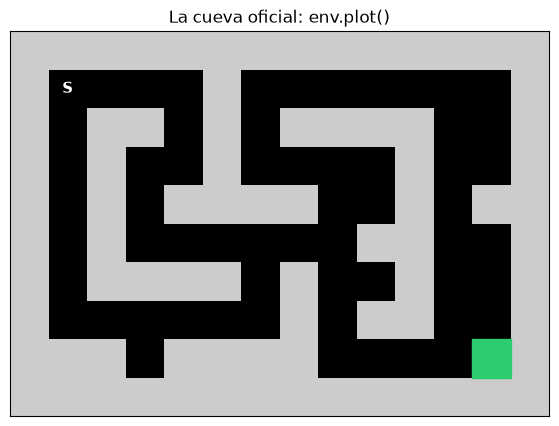

In [22]:
from cave_env import CaveEnv, ACTION_NAMES

env = CaveEnv()
mia = Cueva()
print("estados:", env.nS, "vs", len(mia.libres), "  inicio:", env.start, "vs", mia.reset(),
      "  salida:", env.goal, "vs", mia.pos2s[mia.salida])

rng = np.random.default_rng(3)
env.reset(); mia.reset()
iguales = all(env.step(a)[0] == mia.step(a)[0] for a in rng.integers(0, 4, size=150))
print("¿150 pasos al azar dan los mismos estados?", iguales)

env.plot(title="La cueva oficial: env.plot()")
plt.show()

`env.plot` acepta un mapa de calor (`values=`, un número por casilla), flechas (`policy=`, una acción por casilla) y un recorrido (`path=`, una lista de estados). Por ejemplo, pintemos cada casilla con **cuántas paredes la rodean**, que calculamos en el Paso 6:

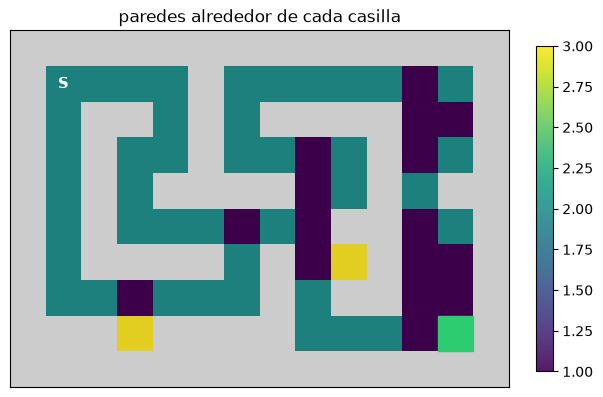

In [23]:
n_paredes = np.array([vecinas[r, c] for (r, c) in env.free])   # un número por estado
env.plot(values=n_paredes, cmap="viridis", title="paredes alrededor de cada casilla")
plt.show()

## Preguntas para pensar

1. En el Paso 6 vimos que un agente al azar choca en casi la mitad de sus pasos. ¿Cambia eso según la casilla? ¿Qué casillas son las "más peligrosas" para chocar?
2. Representamos la cueva como texto, como matriz de 0/1 y como imagen RGB. ¿Cuál le darías a un programa que tiene que *aprender* a salir? ¿Y a una red neuronal convolucional?
3. El jugador del juego no ve `img`: ve `vista`, que va cambiando a medida que choca. ¿Qué información le falta para saber dónde está?

## Próxima clase

Nivelación 0b: **probabilidad**. Le ponemos piso resbaloso a la cueva y nos preguntamos cosas como "¿cuántos pasos voy a tardar *en promedio*?" o "¿dónde estoy, si acabo de chocar?". Es la misma matemática que hay detrás de un clasificador que da probabilidades en vez de respuestas.

---

### Para profundizar

Este notebook es una adaptación libre (con otros ejemplos y otro recorrido) de:

- *CS231n Python/NumPy Tutorial* (Stanford), escrito originalmente por Justin Johnson; versión notebook de Volodymyr Kuleshov e Isaac Caswell; versión Colab de Kevin Zakka y Favour Nerrise. https://cs231n.github.io/python-numpy-tutorial/
- Documentación oficial: NumPy (https://numpy.org/doc/stable/user/absolute_beginners.html) y Matplotlib (https://matplotlib.org/stable/tutorials/index.html).